# ShopExpress — Modélisation avec le dataset original

**Objectif :** reprendre la démarche de modélisation et d’optimisation avec uniquement les variables du fichier `Original.csv` fourni (10 variables explicatives originales, sans `ID`), sans les six variables synthétiques/enrichies.

Convention conservée : **1 = commande en retard ; 0 = commande livrée à temps.**

Le fichier attendu est `shop.csv`, placé dans le même dossier que ce notebook. Le nom de l’expérience MLflow sera `ShopExpress_Original_Dataset` et les résultats seront envoyés vers le dépôt DagsHub de Nadia.

## 1. Installation et importation

Si les bibliothèques sont déjà installées dans votre environnement, vous pouvez simplement exécuter la cellule suivante.

In [1]:
%pip install -q pandas numpy matplotlib scikit-learn joblib mlflow dagshub

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import json
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, precision_recall_curve, RocCurveDisplay
)
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings("ignore", category=FutureWarning)
RANDOM_STATE = 42
TARGET = "Reached.on.Time_Y.N"
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)

pandas: 3.1.0
scikit-learn: 1.9.1


## 2. Chargement du dataset original

In [3]:
DATA_PATH = "Original.csv"  # dataset original fourni
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        "Original.csv introuvable. Placez Original.csv dans le même dossier que original.ipynb."
    )

df = pd.read_csv(DATA_PATH)
print("Dimensions du fichier :", df.shape)
display(df.head())
print("\nColonnes disponibles :")
print(df.columns.tolist())

Dimensions du fichier : (10999, 12)


,ID,Warehouse_block,Mode_of_Shipment,Customer_care_calls,Customer_rating,Cost_of_the_Product,Prior_purchases,Product_importance,Gender,Discount_offered,Weight_in_gms,Reached.on.Time_Y.N
0,1,D,Flight,4,2,177,3,low,F,44,1233,1
1,2,F,Flight,4,5,216,2,low,M,59,3088,1
2,3,A,Flight,2,2,183,4,low,M,48,3374,1
3,4,B,Flight,3,3,176,4,medium,M,10,1177,1
4,5,C,Flight,2,2,184,3,medium,F,46,2484,1



Colonnes disponibles :
['ID', 'Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms', 'Reached.on.Time_Y.N']


## 3. Définition stricte des variables originales

Le fichier `shop.csv` peut aussi contenir des colonnes ajoutées lors des travaux précédents. Pour cette expérience, nous les excluons explicitement. Les variables synthétiques exclues sont : `Distance_km`, `Weather_Condition`, `Traffic_Level`, `Route_Complexity`, `Customer_Country` et `Product_Category`.

L’identifiant `ID` est également exclu des variables explicatives.

In [4]:
synthetic_features = [
    "Distance_km",
    "Weather_Condition",
    "Traffic_Level",
    "Route_Complexity",
    "Customer_Country",
    "Product_Category"
]

original_features_expected = [
    "Warehouse_block",
    "Mode_of_Shipment",
    "Customer_care_calls",
    "Customer_rating",
    "Cost_of_the_Product",
    "Prior_purchases",
    "Product_importance",
    "Gender",
    "Discount_offered",
    "Weight_in_gms"
]

assert TARGET in df.columns, f"La cible {TARGET} est absente du fichier."
missing_original = [c for c in original_features_expected if c not in df.columns]
if missing_original:
    raise ValueError(f"Variables originales manquantes : {missing_original}")

# On ne conserve que les colonnes originales listées + la cible.
# Les colonnes synthétiques et l'identifiant ne peuvent donc pas entrer dans le modèle.
keep_columns = original_features_expected + [TARGET]
df_model = df[keep_columns].copy()

# Conversion/validation de la cible : 1 = retard ; 0 = à temps
df_model = df_model.dropna(subset=[TARGET]).copy()
classes = set(pd.to_numeric(df_model[TARGET], errors="coerce").dropna().unique())
if not classes.issubset({0, 1, 0.0, 1.0}):
    raise ValueError(f"Valeurs inattendues dans la cible : {classes}")
df_model[TARGET] = pd.to_numeric(df_model[TARGET]).astype(int)

original_features = original_features_expected.copy()
print("Nombre de lignes utilisées :", len(df_model))
print("Nombre de variables originales :", len(original_features))
print("Variables utilisées :", original_features)
print("Colonnes non utilisées (dont ID) :", [c for c in df.columns if c not in keep_columns])
print("\nConvention cible : 0 = à temps ; 1 = en retard")
display(df_model[TARGET].value_counts().sort_index().rename(index={0:"À temps (0)", 1:"En retard (1)"}).to_frame("Nombre de commandes"))

Nombre de lignes utilisées : 10999
Nombre de variables originales : 10
Variables utilisées : ['Warehouse_block', 'Mode_of_Shipment', 'Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Product_importance', 'Gender', 'Discount_offered', 'Weight_in_gms']
Colonnes non utilisées (dont ID) : ['ID']

Convention cible : 0 = à temps ; 1 = en retard


,Nombre de commandes
Reached.on.Time_Y.N,
À temps (0),4436
En retard (1),6563


## 4. Exploration descriptive du dataset original

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Warehouse_block,10999,5,F,3666,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Mode_of_Shipment,10999,3,Ship,7462,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Customer_care_calls,10999.0,NaN,NaN,NaN,4.054459,1.14149,2.0,3.0,4.0,5.0,7.0
Customer_rating,10999.0,NaN,NaN,NaN,2.990545,1.413603,1.0,2.0,3.0,4.0,5.0
Cost_of_the_Product,10999.0,NaN,NaN,NaN,210.196836,48.063272,96.0,169.0,214.0,251.0,310.0
Prior_purchases,10999.0,NaN,NaN,NaN,3.567597,1.52286,2.0,3.0,3.0,4.0,10.0
Product_importance,10999,3,low,5297,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,10999,2,F,5545,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Discount_offered,10999.0,NaN,NaN,NaN,13.373216,16.205527,1.0,4.0,7.0,10.0,65.0
Weight_in_gms,10999.0,NaN,NaN,NaN,3634.016729,1635.377251,1001.0,1839.5,4149.0,5050.0,7846.0


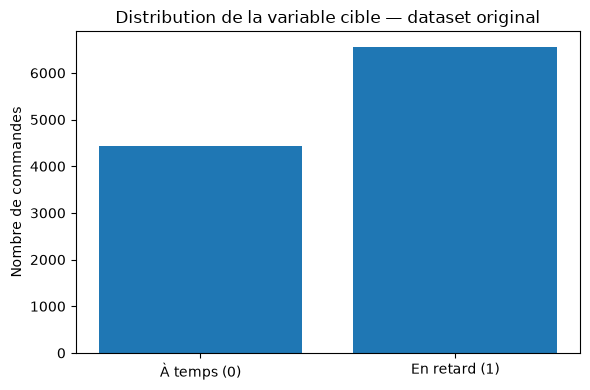

,Valeurs manquantes
Warehouse_block,0
Mode_of_Shipment,0
Customer_care_calls,0
Customer_rating,0
Cost_of_the_Product,0
Prior_purchases,0
Product_importance,0
Gender,0
Discount_offered,0
Weight_in_gms,0


In [5]:
display(df_model[original_features].describe(include="all").T)

class_counts = df_model[TARGET].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(["À temps (0)", "En retard (1)"], [class_counts.get(0, 0), class_counts.get(1, 0)])
plt.title("Distribution de la variable cible — dataset original")
plt.ylabel("Nombre de commandes")
plt.tight_layout()
plt.show()

missing = df_model.isna().sum().sort_values(ascending=False)
display(missing.to_frame("Valeurs manquantes"))

## 5. Séparation des données

Nous reprenons une séparation stratifiée de 70 % entraînement, 15 % validation et 15 % test, avec `random_state=42`. Le jeu de test reste réservé à l’évaluation finale. Cette séparation doit être conservée pour comparer les résultats aux expériences précédentes.

In [6]:
X = df_model[original_features].copy()
y = df_model[TARGET].copy()

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=RANDOM_STATE, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=RANDOM_STATE, stratify=y_temp
)

print("Entraînement :", X_train.shape)
print("Validation :", X_valid.shape)
print("Test :", X_test.shape)
print("\nProportions de la classe 1 :")
print("Train :", round(y_train.mean(), 4), "Validation :", round(y_valid.mean(), 4), "Test :", round(y_test.mean(), 4))

Entraînement : (7699, 10)
Validation : (1650, 10)
Test : (1650, 10)

Proportions de la classe 1 :
Train : 0.5967 Validation : 0.597 Test : 0.5964


## 6. Prétraitement et fonction d’évaluation

Le prétraitement est placé dans un pipeline afin que l’imputation, l’encodage et la standardisation soient ajustés uniquement sur les données d’entraînement de chaque pli de validation croisée.

In [7]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Variables numériques :", numeric_features)
print("Variables catégorielles :", categorical_features)

def evaluate_predictions(y_true, y_pred, y_probability):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision retard (classe 1)": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall retard (classe 1)": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1-score retard (classe 1)": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_probability)
    }

Variables numériques : ['Customer_care_calls', 'Customer_rating', 'Cost_of_the_Product', 'Prior_purchases', 'Discount_offered', 'Weight_in_gms']
Variables catégorielles : ['Warehouse_block', 'Mode_of_Shipment', 'Product_importance', 'Gender']


## 7. Modèles de référence sur les variables originales

Nous évaluons les trois modèles de référence déjà utilisés (régression logistique, arbre de décision et Random Forest), puis Gradient Boosting afin de pouvoir vérifier s’il reste performant sans les variables synthétiques.

In [8]:
baseline_models = {
    "Régression logistique": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
    "Arbre de décision": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE)
}

baseline_results = []
baseline_fitted = {}
for name, estimator in baseline_models.items():
    pipe = Pipeline([("preprocessor", preprocessor), ("model", estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_valid)
    prob = pipe.predict_proba(X_valid)[:, 1]
    metrics = evaluate_predictions(y_valid, pred, prob)
    metrics["Modèle"] = name
    baseline_results.append(metrics)
    baseline_fitted[name] = pipe

baseline_df = pd.DataFrame(baseline_results).set_index("Modèle").sort_values("F1-score retard (classe 1)", ascending=False)
display(baseline_df.round(4))

,Accuracy,Precision retard (classe 1),Recall retard (classe 1),F1-score retard (classe 1),ROC-AUC
Modèle,,,,,
Régression logistique,0.6442,0.7163,0.6690,0.6919,0.7247
Arbre de décision,0.6279,0.6959,0.6690,0.6822,0.6180
Random Forest,0.6352,0.7350,0.6081,0.6656,0.7167
Gradient Boosting,0.6673,0.8964,0.5005,0.6423,0.7324


## 8. Optimisation des hyperparamètres par validation croisée

La recherche utilise uniquement `X_train` et `y_train`. Le score de sélection est le F1-score de la classe positive 1 (retard). La validation sert ensuite à comparer les modèles optimisés.

In [9]:
param_grids = {
    "Régression logistique": {
        "model": LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
        "params": {"model__C": [0.01, 0.1, 1, 10], "model__class_weight": [None, "balanced"]}
    },
    "Arbre de décision": {
        "model": DecisionTreeClassifier(random_state=RANDOM_STATE),
        "params": {"model__max_depth": [4, 8, 12, None], "model__min_samples_leaf": [3, 5, 10, 20], "model__class_weight": [None, "balanced"]}
    },
    "Random Forest": {
        "model": RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
        "params": {"model__n_estimators": [100, 200], "model__max_depth": [8, 15, None], "model__min_samples_leaf": [3, 5, 10], "model__class_weight": [None, "balanced"]}
    },
    "Gradient Boosting": {
        "model": GradientBoostingClassifier(random_state=RANDOM_STATE),
        "params": {"model__n_estimators": [100, 200], "model__learning_rate": [0.03, 0.05, 0.1], "model__max_depth": [2, 3], "model__min_samples_leaf": [5, 10]}
    }
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
optimized_models = {}
optimization_rows = []

for name, config in param_grids.items():
    print("Optimisation :", name)
    pipe = Pipeline([("preprocessor", preprocessor), ("model", config["model"])])
    search = GridSearchCV(pipe, config["params"], scoring="f1", cv=cv, n_jobs=-1, refit=True)
    search.fit(X_train, y_train)
    best_pipe = search.best_estimator_
    valid_pred = best_pipe.predict(X_valid)
    valid_prob = best_pipe.predict_proba(X_valid)[:, 1]
    row = evaluate_predictions(y_valid, valid_pred, valid_prob)
    row.update({"Modèle": name, "F1-score CV": search.best_score_, "Meilleurs paramètres": search.best_params_})
    optimization_rows.append(row)
    optimized_models[name] = best_pipe

optimization_df = pd.DataFrame(optimization_rows).sort_values("F1-score retard (classe 1)", ascending=False)
display(optimization_df.round(4))

Optimisation : Régression logistique
Optimisation : Arbre de décision
Optimisation : Random Forest
Optimisation : Gradient Boosting


,Accuracy,Precision retard (classe 1),Recall retard (classe 1),F1-score retard (classe 1),ROC-AUC,Modèle,F1-score CV,Meilleurs paramètres
0,0.6558,0.7174,0.6985,0.7078,0.7310,Régression logistique,0.7009,"{'model__C': 0.01, 'model__class_weight': None}"
3,0.6861,0.8060,0.6244,0.7037,0.7578,Gradient Boosting,0.6922,"{'model__learning_rate': 0.03, 'model__max_dep..."
1,0.6327,0.7089,0.6528,0.6797,0.6613,Arbre de décision,0.7090,"{'model__class_weight': 'balanced', 'model__ma..."
2,0.6455,0.7674,0.5827,0.6624,0.7188,Random Forest,0.6868,"{'model__class_weight': None, 'model__max_dept..."


## 9. Sélection du meilleur modèle sur validation

Le modèle est choisi uniquement à partir du F1-score de validation, sans consulter le jeu de test.

In [10]:
best_row = optimization_df.loc[optimization_df["F1-score retard (classe 1)"].idxmax()]
best_model_name = best_row["Modèle"]
best_model = optimized_models[best_model_name]
best_params = best_row["Meilleurs paramètres"]

print("Meilleur modèle sur validation :", best_model_name)
print("F1-score validation :", round(best_row["F1-score retard (classe 1)"], 4))
print("Meilleurs paramètres :", best_params)

Meilleur modèle sur validation : Régression logistique
F1-score validation : 0.7078
Meilleurs paramètres : {'model__C': 0.01, 'model__class_weight': None}


## 10. Choix du seuil sur validation

Le seuil 0,50 est conservé comme référence. Un autre seuil peut être choisi sur la validation pour maximiser le F1-score de la classe 1. Le seuil choisi sera ensuite figé avant l’évaluation sur le test.

In [11]:
valid_probabilities = best_model.predict_proba(X_valid)[:, 1]
precision_values, recall_values, thresholds = precision_recall_curve(y_valid, valid_probabilities, pos_label=1)
f1_values = 2 * precision_values[:-1] * recall_values[:-1] / (precision_values[:-1] + recall_values[:-1] + 1e-12)
best_threshold_index = int(np.argmax(f1_values))
best_threshold = float(thresholds[best_threshold_index])

print(f"Seuil retenu sur validation : {best_threshold:.3f}")
print(f"F1 validation au seuil choisi : {f1_values[best_threshold_index]:.4f}")
print(f"Précision validation : {precision_values[best_threshold_index]:.4f}")
print(f"Rappel validation : {recall_values[best_threshold_index]:.4f}")

threshold_rows = []
for threshold in [0.35, 0.40, 0.45, 0.50, 0.55, 0.60, best_threshold]:
    pred = (valid_probabilities >= threshold).astype(int)
    m = evaluate_predictions(y_valid, pred, valid_probabilities)
    m["Seuil"] = threshold
    threshold_rows.append(m)
threshold_df = pd.DataFrame(threshold_rows).drop_duplicates(subset=["Seuil"]).sort_values("Seuil")
display(threshold_df[["Seuil", "Accuracy", "Precision retard (classe 1)", "Recall retard (classe 1)", "F1-score retard (classe 1)"]].round(4))

Seuil retenu sur validation : 0.328
F1 validation au seuil choisi : 0.7483
Précision validation : 0.6026
Rappel validation : 0.9868


,Seuil,Accuracy,Precision retard (classe 1),Recall retard (classe 1),F1-score retard (classe 1)
6,0.3284,0.6036,0.6026,0.9868,0.7483
0,0.3500,0.6042,0.6053,0.9685,0.7450
1,0.4000,0.6139,0.6198,0.9137,0.7386
2,0.4500,0.6333,0.6547,0.8162,0.7266
3,0.5000,0.6558,0.7174,0.6985,0.7078
4,0.5500,0.6527,0.7901,0.5695,0.6619
5,0.6000,0.6521,0.8856,0.4792,0.6219


## 11. Évaluation finale sur le jeu de test

Le jeu de test n’est utilisé qu’ici, après la sélection du modèle et du seuil. Les deux seuils (0,50 et seuil optimisé) sont présentés pour rendre le compromis visible.

Modèle retenu : Régression logistique


,Accuracy,Precision retard (classe 1),Recall retard (classe 1),F1-score retard (classe 1),ROC-AUC
"Seuil standard 0,50",0.6255,0.6819,0.6972,0.6894,0.7124
Seuil optimisé 0.328,0.5945,0.5978,0.9787,0.7422,0.7124


Rapport de classification — seuil optimisé
               precision    recall  f1-score   support

  À temps (0)       0.46      0.03      0.05       666
En retard (1)       0.60      0.98      0.74       984

     accuracy                           0.59      1650
    macro avg       0.53      0.50      0.40      1650
 weighted avg       0.54      0.59      0.46      1650



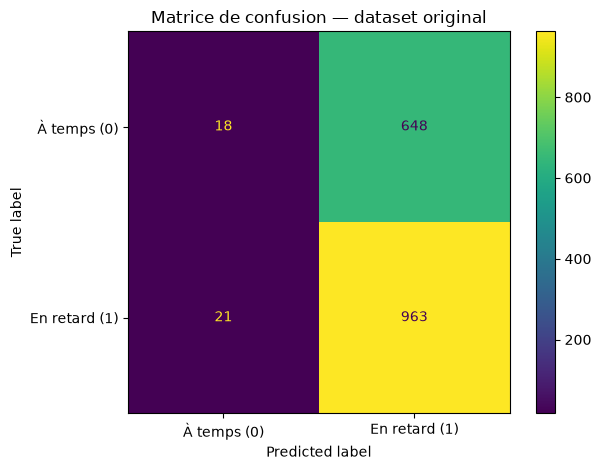

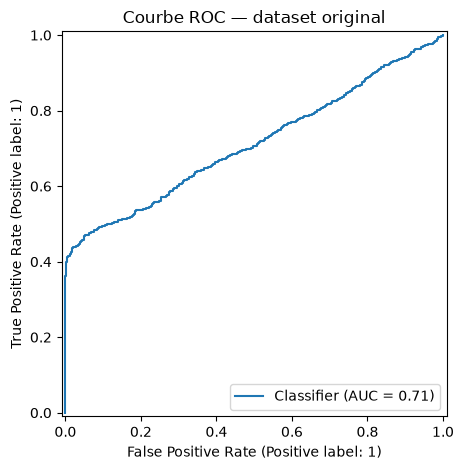

In [12]:
test_probabilities = best_model.predict_proba(X_test)[:, 1]
predictions_050 = (test_probabilities >= 0.50).astype(int)
predictions_tuned = (test_probabilities >= best_threshold).astype(int)

metrics_050 = evaluate_predictions(y_test, predictions_050, test_probabilities)
metrics_tuned = evaluate_predictions(y_test, predictions_tuned, test_probabilities)
test_comparison = pd.DataFrame([metrics_050, metrics_tuned], index=["Seuil standard 0,50", f"Seuil optimisé {best_threshold:.3f}"])
print("Modèle retenu :", best_model_name)
display(test_comparison.round(4))

print("Rapport de classification — seuil optimisé")
print(classification_report(y_test, predictions_tuned, labels=[0, 1], target_names=["À temps (0)", "En retard (1)"], zero_division=0))
ConfusionMatrixDisplay.from_predictions(y_test, predictions_tuned, labels=[0, 1], display_labels=["À temps (0)", "En retard (1)"], values_format="d")
plt.title("Matrice de confusion — dataset original")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, test_probabilities)
plt.title("Courbe ROC — dataset original")
plt.tight_layout()
plt.show()

final_metrics = metrics_tuned.copy()

## 12. Importance des variables originales

L’importance par permutation est calculée sur la validation. Elle mesure la dépendance prédictive du modèle aux variables, sans démontrer de causalité.

,Variable,Importance moyenne,Écart-type
9,Weight_in_gms,0.0234,0.0069
8,Discount_offered,0.0141,0.0087
1,Mode_of_Shipment,0.0025,0.0010
3,Customer_rating,0.0015,0.0021
0,Warehouse_block,0.0010,0.0022
6,Product_importance,0.0009,0.0025
5,Prior_purchases,-0.0001,0.0048
7,Gender,-0.0008,0.0015
4,Cost_of_the_Product,-0.0014,0.0036
2,Customer_care_calls,-0.0032,0.0020


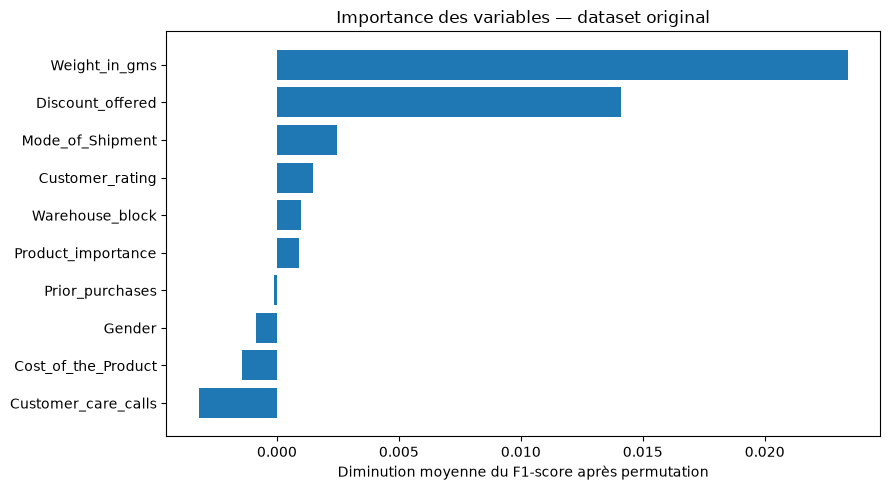

In [13]:
permutation = permutation_importance(
    best_model, X_valid, y_valid,
    n_repeats=10, random_state=RANDOM_STATE,
    scoring="f1", n_jobs=-1
)
importance_df = pd.DataFrame({
    "Variable": original_features,
    "Importance moyenne": permutation.importances_mean,
    "Écart-type": permutation.importances_std
}).sort_values("Importance moyenne", ascending=False)
display(importance_df.round(4))

plot_df = importance_df.sort_values("Importance moyenne").tail(10)
plt.figure(figsize=(9, 5))
plt.barh(plot_df["Variable"], plot_df["Importance moyenne"])
plt.xlabel("Diminution moyenne du F1-score après permutation")
plt.title("Importance des variables — dataset original")
plt.tight_layout()
plt.show()

## 13. Sauvegarde du modèle et des résultats

Le paquet sauvegardé contient le pipeline complet, les variables originales, la convention de la cible et le seuil de décision.

In [14]:
model_package = {
    "model": best_model,
    "features": original_features,
    "target": TARGET,
    "positive_class": 1,
    "class_definition": {"1": "En retard", "0": "À temps"},
    "model_name": best_model_name,
    "configuration": best_params,
    "decision_threshold": best_threshold,
    "dataset_version": "original",
    "random_state": RANDOM_STATE
}
joblib.dump(model_package, "shopexpress_modele_original.joblib")
optimization_df.to_csv("resultats_optimisation_original.csv", index=False)
test_comparison.to_csv("resultats_test_original.csv")
importance_df.to_csv("importance_variables_original.csv", index=False)
print("Fichiers sauvegardés.")

Fichiers sauvegardés.


## 14. Suivi des expériences avec MLflow sur DagsHub — Nadia

Cette expérience est envoyée au dépôt DagsHub `nadiagouroubera40-debug/Delais_de_Livraison`. Vous devez avoir un accès contributeur à ce dépôt. L’authentification est gérée par `dagshub.init()` ; si DagsHub demande une autorisation, suivez l’invite. **Ne mettez jamais votre token dans le notebook ni sur GitHub.**

In [15]:
import dagshub
import mlflow
import mlflow.sklearn

DAGSHUB_OWNER = "nadiagouroubera40-debug"
DAGSHUB_REPO = "Delais_de_Livraison"
MLFLOW_EXPERIMENT = "ShopExpress_Original_Dataset"

# Configure le tracking distant et l'authentification DagsHub.
dagshub.init(repo_owner=DAGSHUB_OWNER, repo_name=DAGSHUB_REPO, mlflow=True)
mlflow.set_experiment(MLFLOW_EXPERIMENT)

print("Tracking URI :", mlflow.get_tracking_uri())
print("Expérience :", MLFLOW_EXPERIMENT)

Accessing as nadiagouroubera40-debug

Initialized MLflow to track repo "nadiagouroubera40-debug/Delais_de_Livraison"

Repository nadiagouroubera40-debug/Delais_de_Livraison initialized!

Tracking URI : https://dagshub.com/nadiagouroubera40-debug/Delais_de_Livraison.mlflow
Expérience : ShopExpress_Original_Dataset


In [20]:
import numpy as np

colonnes_metriques = [
    "Accuracy",
    "Precision retard (classe 1)",
    "Recall retard (classe 1)",
    "F1-score retard (classe 1)",
    "ROC-AUC",
    "F1-score CV"
]

for colonne in colonnes_metriques:
    print(f"\n{colonne}")
    print(optimization_df[colonne])

    valeurs = optimization_df[colonne].astype(float)

    if not np.isfinite(valeurs).all():
        print("ATTENTION : valeurs NaN ou infinies détectées")
    else:
        print("OK : valeurs numériques valides")


Accuracy
0    0.655758
3    0.686061
1    0.632727
2    0.645455
Name: Accuracy, dtype: float64
OK : valeurs numériques valides

Precision retard (classe 1)
0    0.717414
3    0.806029
1    0.708931
2    0.767380
Name: Precision retard (classe 1), dtype: float64
OK : valeurs numériques valides

Recall retard (classe 1)
0    0.698477
3    0.624365
1    0.652792
2    0.582741
Name: Recall retard (classe 1), dtype: float64
OK : valeurs numériques valides

F1-score retard (classe 1)
0    0.707819
3    0.703661
1    0.679704
2    0.662435
Name: F1-score retard (classe 1), dtype: float64
OK : valeurs numériques valides

ROC-AUC
0    0.731045
3    0.757757
1    0.661299
2    0.718843
Name: ROC-AUC, dtype: float64
OK : valeurs numériques valides

F1-score CV
0    0.700876
3    0.692191
1    0.708964
2    0.686821
Name: F1-score CV, dtype: float64
OK : valeurs numériques valides


In [21]:
import re

def nettoyer_nom_metrique(nom):
    nom = nom.lower()
    nom = re.sub(r"[^a-zA-Z0-9_]", "_", nom)
    nom = re.sub(r"_+", "_", nom)
    return nom.strip("_")[:100]

print("Fonction de nettoyage prête !")

Fonction de nettoyage prête !


In [23]:
import os

fichiers_a_enregistrer = [
    "shopexpress_modele_original.joblib",
    "resultats_optimisation_original.csv",
    "resultats_test_original.csv",
    "importance_variables_original.csv"
]

for fichier in fichiers_a_enregistrer:
    assert os.path.isfile(fichier), (
        f"Fichier manquant : {fichier}"
    )

print("Tous les fichiers sont prêts pour MLflow.")

Tous les fichiers sont prêts pour MLflow.


In [24]:
with mlflow.start_run(
    run_name=f"Original_FINAL_{best_model_name}_v2"
):

    mlflow.log_param("dataset", "original")
    mlflow.log_param("model", best_model_name)
    mlflow.log_param("target", TARGET)
    mlflow.log_param("positive_class", 1)
    mlflow.log_param(
        "decision_threshold",
        float(best_threshold)
    )

    mlflow.log_param(
        "features",
        json.dumps(original_features, ensure_ascii=True)
    )

    mlflow.log_param(
        "best_params",
        json.dumps(best_params, default=str)
    )

    mlflow.log_param(
        "split",
        "70_train_15_validation_15_test"
    )

    for metric, value in metrics_tuned.items():
        valeur = float(value)

        if np.isfinite(valeur):
            mlflow.log_metric(
                nettoyer_nom_metrique(metric),
                valeur
            )

    for fichier in fichiers_a_enregistrer:
        mlflow.log_artifact(fichier)

    # Correction de la sérialisation
    mlflow.sklearn.log_model(
        sk_model=best_model,
        artifact_path="model",
        skops_trusted_types=["numpy.dtype"]
    )

    print("Modèle final enregistré avec succès !")

2026/11/13 10:31:03 WARNING mlflow.models.model: `artifact_path` is deprecated. Please use `name` instead.


Modèle final enregistré avec succès !
🏃 View run Original_FINAL_Régression logistique_v2 at: https://dagshub.com/nadiagouroubera40-debug/Delais_de_Livraison.mlflow/#/experiments/1/runs/d85969f4a50b4e91952d64cf9ead0028
🧪 View experiment at: https://dagshub.com/nadiagouroubera40-debug/Delais_de_Livraison.mlflow/#/experiments/1


## 15. Bilan de l’expérience originale

À compléter après exécution :
- meilleur modèle sur validation ;
- F1-score, précision et rappel sur le test ;
- seuil retenu ;
- variables les plus importantes ;
- comparaison avec le notebook utilisant les variables enrichies.

**Important :** ne comparez pas le F1-score de validation d’un notebook au F1-score de test de l’autre. Pour la comparaison finale, utilisez les métriques du jeu de test, le même découpage, la même définition de la cible et les mêmes seuils (0,50 et seuil choisi sur validation).